In [1]:
import pandas as pd
import matplotlib.pyplot as plt

carreras = pd.read_csv("../data/clean/carreras.csv", parse_dates=["fecha"])
elite = pd.read_csv("../data/clean/elite.csv", parse_dates=["fecha"])

# para el analisis quito las competiciones, ahi voy a tope y no es comparable con entrenar
entrenos = carreras[~carreras["es_competicion"]].dropna(subset=["temp"]).copy()
print(entrenos.shape)

(293, 19)


            count  median
tramo_temp               
<10            60   310.5
10-15          53   302.8
15-20          70   311.9
20-25          60   317.6
>25            50   325.6
con mas de 20 grados voy 11.5 s/km mas lento


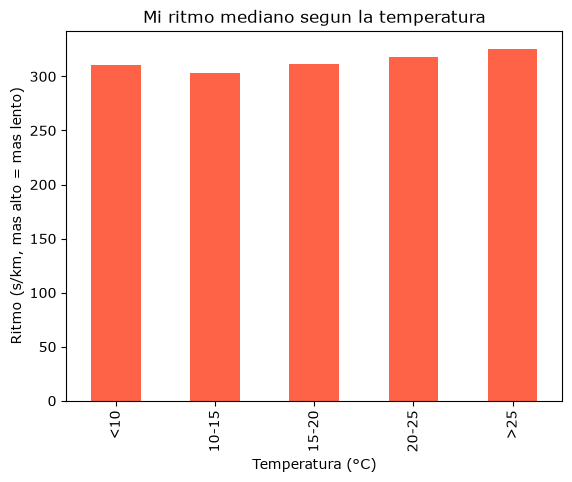

In [2]:
# hago tramos de temperatura y miro mi ritmo mediano en cada uno
entrenos["tramo_temp"] = pd.cut(entrenos["temp"], bins=[-5, 10, 15, 20, 25, 40],
                                labels=["<10", "10-15", "15-20", "20-25", ">25"])
tabla_h1 = entrenos.groupby("tramo_temp", observed=True)["ritmo_s_km"].agg(["count", "median"]).round(1)
print(tabla_h1)

# la hipotesis en un numero: mediana con calor menos mediana sin calor
calor = entrenos[entrenos["temp"] > 20]["ritmo_s_km"].median()
fresco = entrenos[entrenos["temp"] <= 20]["ritmo_s_km"].median()
print(f"con mas de 20 grados voy {calor - fresco:.1f} s/km mas lento")

tabla_h1["median"].plot(kind="bar", color="tomato")
plt.title("Mi ritmo mediano segun la temperatura")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Ritmo (s/km, mas alto = mas lento)")
plt.show()

### Conclusión H1: el calor
Sí, el calor me frena. Con más de 20 °C mi ritmo mediano es 5:20/km, y con 20 °C o menos es 5:09/km. Son 11,5 s/km de diferencia, así que la hipótesis se cumple, aunque por poco (había puesto el listón en 10).

Donde mejor corro es entre 10 y 15 °C (5:03/km). Por encima de 25 °C me voy a 5:26/km. Lo que no esperaba es que el frío tampoco me venga bien: por debajo de 10 °C también voy algo más lento (5:10/km).

Ojo: la correlación entre temperatura y ritmo es baja (0,18). El calor influye, pero no es lo único. El tipo de entreno o lo cansado que esté también cuentan, y eso Strava no lo sabe.

276 entrenos con pulso
            carreras  pulso_mediano  ritmo_mediano  metros_por_latido
tramo_temp                                                           
<10               59          138.1         310.40               1.40
10-15             53          142.8         302.80               1.41
15-20             66          137.3         310.75               1.41
20-25             55          138.4         313.60               1.38
>25               43          136.5         328.00               1.35
con el mismo pulso (<=145) voy 15.8 s/km mas lento con mas de 20 grados


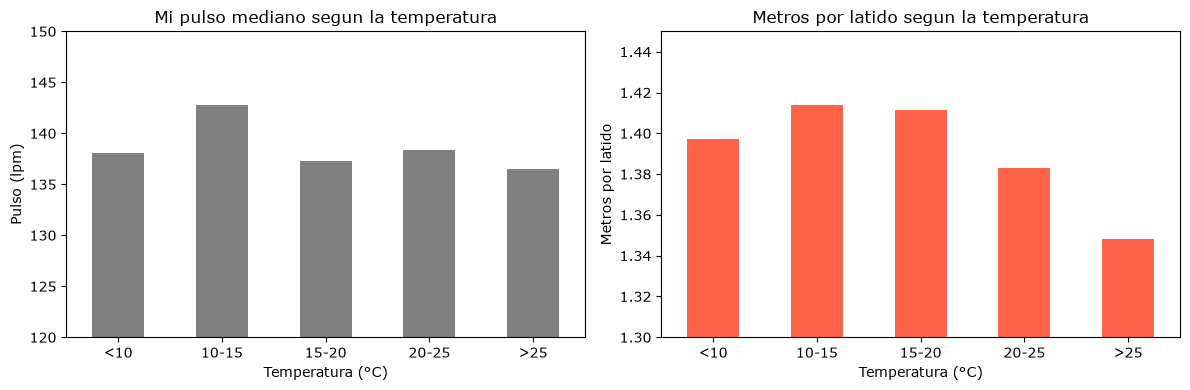

In [3]:
# H1b: calor y pulso. ¿con calor me sube el pulso o voy mas lento con el mismo pulso?
pulso = entrenos.dropna(subset=["pulso"]).copy()
print(len(pulso), "entrenos con pulso")

# metros que avanzo por cada latido: si baja, soy menos eficiente
pulso["metros_por_latido"] = (1000 / pulso["ritmo_s_km"] * 60) / pulso["pulso"]
print(pulso.groupby("tramo_temp", observed=True).agg(carreras=("pulso", "size"),
                                                     pulso_mediano=("pulso", "median"),
                                                     ritmo_mediano=("ritmo_s_km", "median"),
                                                     metros_por_latido=("metros_por_latido", "median")).round(2))

# comparo a igual esfuerzo: solo rodajes suaves (pulso de 145 o menos)
suave = pulso[pulso["pulso"] <= 145]
con_calor = suave[suave["temp"] > 20]["ritmo_s_km"].median()
sin_calor = suave[suave["temp"] <= 20]["ritmo_s_km"].median()
print(f"con el mismo pulso (<=145) voy {con_calor - sin_calor:.1f} s/km mas lento con mas de 20 grados")

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
pulso.groupby("tramo_temp", observed=True)["pulso"].median().plot(kind="bar", ax=ejes[0], color="grey")
ejes[0].set_title("Mi pulso mediano segun la temperatura")
ejes[0].set_ylabel("Pulso (lpm)")
ejes[0].set_ylim(120, 150)
ejes[0].set_xlabel("Temperatura (°C)")
pulso.groupby("tramo_temp", observed=True)["metros_por_latido"].median().plot(kind="bar", ax=ejes[1], color="tomato")
ejes[1].set_title("Metros por latido segun la temperatura")
ejes[1].set_ylabel("Metros por latido")
ejes[1].set_ylim(1.3, 1.45)
ejes[1].set_xlabel("Temperatura (°C)")
for eje in ejes:
    eje.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### Conclusión H1b: calor y pulso
Esperaba que con calor me subiera el pulso, pero no: mi pulso mediano es casi el mismo con y sin calor (unos 138 lpm). Lo que cambia es el ritmo. Corro por sensaciones, y cuando hace calor aflojo sin darme cuenta para mantener el mismo esfuerzo.

La prueba está en comparar a igual esfuerzo. En rodajes suaves (pulso de 145 o menos) voy unos 16 s/km más lento con más de 20 °C. Y los metros que avanzo por cada latido bajan de 1,41 a 1,35 por encima de 25 °C, un 4 % menos de eficiencia.

Esto hace la H1 más sólida: con calor no voy más lento porque me esfuerce menos, sino porque el mismo esfuerzo me da para menos. Ojo: es el pulso medio de la actividad, que mide el reloj en la muñeca, no un pulsómetro de pecho.

tipo_zapa  competicion  diario
tramo_km                      
<8 km               10      94
8-12 km              4      77
>12 km               5      66
tipo_zapa  competicion  diario  diferencia
tramo_km                                  
<8 km            270.2   338.8        68.6
8-12 km          276.9   300.7        23.8
>12 km           303.8   309.4         5.6


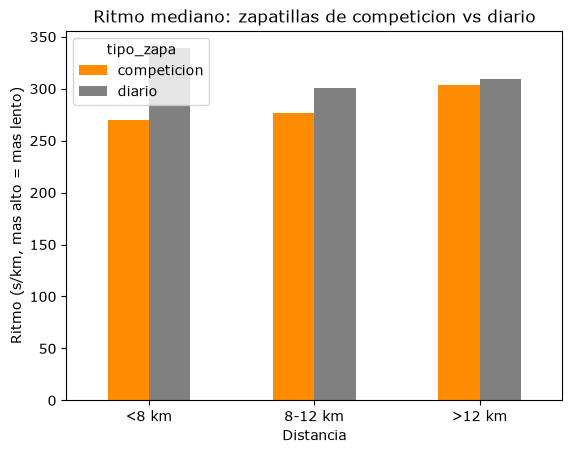

In [4]:
# solo comparo diario contra competicion (fuera trail y sin dato)
zapas = entrenos[entrenos["tipo_zapa"].isin(["diario", "competicion"])].copy()
zapas["tramo_km"] = pd.cut(zapas["km"], bins=[0, 8, 12, 50], labels=["<8 km", "8-12 km", ">12 km"])

# cuantas carreras hay en cada grupo (para saber si me puedo fiar)
print(pd.crosstab(zapas["tramo_km"], zapas["tipo_zapa"]))

# ritmo mediano por tramo y tipo de zapatilla
tabla_h2 = zapas.pivot_table(index="tramo_km", columns="tipo_zapa", values="ritmo_s_km",
                             aggfunc="median", observed=True).round(1)
tabla_h2["diferencia"] = tabla_h2["diario"] - tabla_h2["competicion"]
print(tabla_h2)

tabla_h2[["competicion", "diario"]].plot(kind="bar", color=["darkorange", "grey"])
plt.title("Ritmo mediano: zapatillas de competicion vs diario")
plt.xlabel("Distancia")
plt.ylabel("Ritmo (s/km, mas alto = mas lento)")
plt.xticks(rotation=0)
plt.show()

### Conclusión H2: las zapatillas
Sí, con las de placa voy más rápido: unos 32 s/km de mediana (4:40/km contra 5:12/km). La diferencia depende mucho de la distancia: en menos de 8 km son 69 s, entre 8 y 12 km son 24 s y en más de 12 km solo 6 s.

Pero no todo es mérito de la zapatilla. Me pongo las de placa los días que voy a apretar (series, tempo), así que parte de la diferencia es el tipo de entreno. Además hay pocos datos: solo 19 entrenos con placa, casi todos con las Zoom Fly 5. En las tiradas largas, que es donde más se parecen los entrenos, la ventaja casi desaparece.

Curiosidad: todas mis carreras de 10K y dos de mis medias fueron con las Zoom Fly, pero la Maratón de Madrid 2026 la corrí con las Vomero.

           carreras  ritmo_mediano  temp_media  km_mediana
estacion                                                  
invierno         72          309.8         8.3        10.0
primavera        79          310.6        17.0        10.0
verano           86          316.1        24.4         7.5
otoño            56          314.3        18.1         6.9
en otoño-invierno voy 2.6 s/km mas rapido


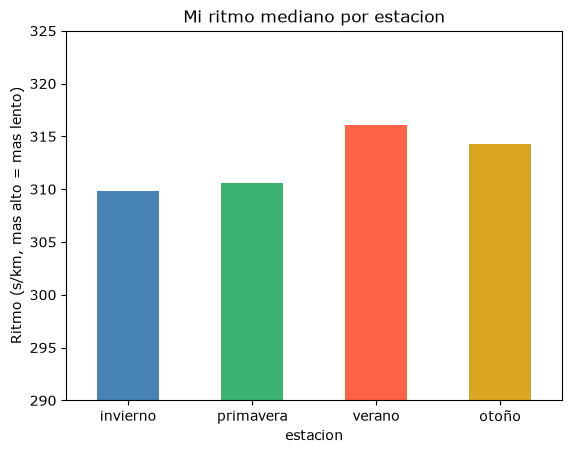

In [5]:
# ritmo, temperatura y distancia media de cada estacion
orden = ["invierno", "primavera", "verano", "otoño"]
tabla_h3 = entrenos.groupby("estacion").agg(carreras=("ritmo_s_km", "size"),
                                             ritmo_mediano=("ritmo_s_km", "median"),
                                             temp_media=("temp", "mean"),
                                             km_mediana=("km", "median")).reindex(orden).round(1)
print(tabla_h3)

# la hipotesis: otoño + invierno contra primavera + verano
frio = entrenos[entrenos["estacion"].isin(["otoño", "invierno"])]["ritmo_s_km"].median()
calido = entrenos[entrenos["estacion"].isin(["primavera", "verano"])]["ritmo_s_km"].median()
print(f"en otoño-invierno voy {calido - frio:.1f} s/km mas rapido")

tabla_h3["ritmo_mediano"].plot(kind="bar", color=["steelblue", "mediumseagreen", "tomato", "goldenrod"])
plt.title("Mi ritmo mediano por estacion")
plt.ylabel("Ritmo (s/km, mas alto = mas lento)")
plt.ylim(290, 325)  # si no, las barras parecen iguales
plt.xticks(rotation=0)
plt.show()

### Conclusión H3: las estaciones
No se cumple, o se cumple tan poco que no cuenta. En otoño-invierno voy solo 2,6 s/km más rápido que en primavera-verano. El invierno sí es mi mejor estación (5:10/km) y el verano la peor (5:16/km), pero son 6 segundos.

El otoño sale más lento de lo que esperaba. En mis datos es una estación templada (18 °C de media) y en ella hago salidas más cortas (6,9 km de mediana). Mi conclusión es que lo que me frena es la temperatura del día (H1), no la estación en sí. Un día fresco de verano corro igual que en invierno.

        carreras  ritmo_mediano  temp_media
franja                                     
mañana       115          313.4        15.0
tarde        168          310.5        18.1


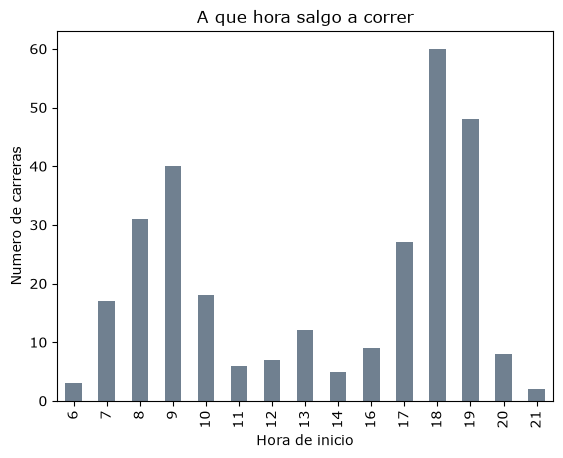

franja      mañana  tarde
tramo_temp               
<15          310.4  302.1
15-25        313.5  313.3
>25          344.5  318.3


In [6]:
# casi no corro de noche (10 carreras), asi que comparo mañana contra tarde
franjas = entrenos[entrenos["franja"].isin(["mañana", "tarde"])].copy()
print(franjas.groupby("franja").agg(carreras=("ritmo_s_km", "size"),
                                    ritmo_mediano=("ritmo_s_km", "median"),
                                    temp_media=("temp", "mean")).round(1))

# a que horas salgo a correr
entrenos["fecha"].dt.hour.value_counts().sort_index().plot(kind="bar", color="slategray")
plt.title("A que hora salgo a correr")
plt.xlabel("Hora de inicio")
plt.ylabel("Numero de carreras")
plt.show()

# comparo a igual temperatura, porque por la tarde suele hacer mas calor
franjas["tramo_temp"] = pd.cut(franjas["temp"], bins=[-5, 15, 25, 40], labels=["<15", "15-25", ">25"])
print(franjas.pivot_table(index="tramo_temp", columns="franja", values="ritmo_s_km",
                          aggfunc="median", observed=True).round(1))

### Conclusión H4: mañana o tarde
No se cumple. Por la tarde voy un poco más rápido (5:10/km) que por la mañana (5:13/km), aunque por la tarde hace de media 3 °C más.

Tengo dos picos de horario muy claros: de 8 a 9 de la mañana (sobre todo fines de semana) y de 18 a 19 h, al salir de trabajar. A igual temperatura, la tarde gana o empata. Seguramente es porque a primera hora salgo en ayunas o sin calentar, y por la tarde el cuerpo ya está activado. Ojo: con más de 25 °C solo tengo 9 salidas de mañana, así que ese tramo no es fiable.

                   corredor  correlacion  s_km_por_5_grados  indice_calor
0                        Yo         0.18                4.5             2
1  Elite (Berlin + Londres)        -0.03               -0.3             1


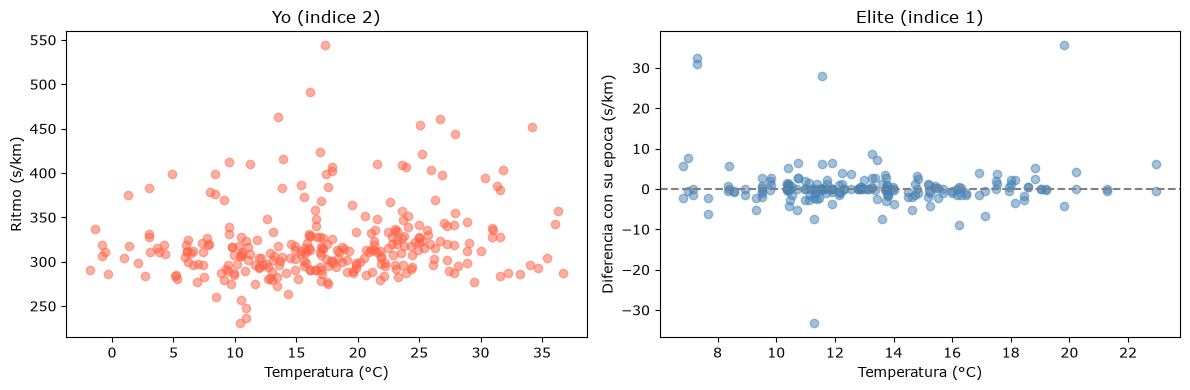

In [7]:
import numpy as np

def indice_calor(corr):
    # paso la correlacion a una nota del 1 al 5
    if corr < 0.1:
        return 1
    elif corr < 0.3:
        return 2
    elif corr < 0.5:
        return 3
    elif corr < 0.7:
        return 4
    else:
        return 5

# --- yo ---
corr_yo = entrenos["temp"].corr(entrenos["ritmo_s_km"])
pendiente_yo = np.polyfit(entrenos["temp"], entrenos["ritmo_s_km"], 1)[0]  # s/km por cada grado

# --- elite: quito el efecto de la epoca ---
elite["year"] = elite["fecha"].dt.year
elite = elite.sort_values("year")
# para cada maraton y sexo, la mediana de las 9 ediciones de alrededor
elite["tendencia"] = elite.groupby(["maraton", "sexo"])["ritmo_s_km"].transform(
    lambda x: x.rolling(9, center=True, min_periods=3).median())
# positivo = ese año fueron mas lentos de lo normal para su epoca
elite["diferencia"] = elite["ritmo_s_km"] - elite["tendencia"]

corr_elite = elite["temp"].corr(elite["diferencia"])
pendiente_elite = np.polyfit(elite["temp"], elite["diferencia"], 1)[0]

resumen = pd.DataFrame({
    "corredor": ["Yo", "Elite (Berlin + Londres)"],
    "correlacion": [round(corr_yo, 2), round(corr_elite, 2)],
    "s_km_por_5_grados": [round(pendiente_yo * 5, 1), round(pendiente_elite * 5, 1)],
    "indice_calor": [indice_calor(corr_yo), indice_calor(corr_elite)],
})
print(resumen)

# grafico: yo y la elite lado a lado
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].scatter(entrenos["temp"], entrenos["ritmo_s_km"], alpha=0.5, color="tomato")
ejes[0].set_title(f"Yo (indice {indice_calor(corr_yo)})")
ejes[0].set_xlabel("Temperatura (°C)")
ejes[0].set_ylabel("Ritmo (s/km)")
ejes[1].scatter(elite["temp"], elite["diferencia"], alpha=0.5, color="steelblue")
ejes[1].axhline(0, color="grey", linestyle="--")
ejes[1].set_title(f"Elite (indice {indice_calor(corr_elite)})")
ejes[1].set_xlabel("Temperatura (°C)")
ejes[1].set_ylabel("Diferencia con su epoca (s/km)")
plt.tight_layout()
plt.show()

### Conclusión H5: índice de sensibilidad al calor
El calor me afecta más a mí que a la élite. Mi índice es 2 sobre 5: pierdo unos 4,5 s/km por cada 5 °C más, un 1,4 % de mi ritmo. Los ganadores de Berlín y Londres tienen un 1: una vez quitado el efecto de la época (los tiempos han bajado mucho con los años), la temperatura no explica nada de su ritmo.

Tiene truco. Las maratones grandes se corren a propósito en fechas frescas: en Berlín y Londres casi nunca se han pasado de 23 °C a la hora de carrera, y yo he entrenado a 36 °C. Además, el ritmo de un ganador depende mucho de la táctica (liebres, carrera lenta y sprint final), no solo del clima. Aun así, la idea vale: un élite está adaptado y su ritmo apenas cambia con el tiempo que haga, y a un corredor popular como yo sí le pasa factura.

## Conclusiones
- **H1 · Calor: se cumple.** Por encima de 20 °C voy 11,5 s/km más lento. Mi temperatura ideal está entre 10 y 15 °C.
- **H1b · Pulso:** con calor no me sube el pulso, me baja el ritmo. Con el mismo pulso voy unos 16 s/km más lento por encima de 20 °C.
- **H2 · Zapatillas: se cumple, con matices.** Con placa voy 32 s/km más rápido, pero porque las uso los días de calidad. En tiradas largas la diferencia es de 6 s.
- **H3 · Estaciones: no se cumple.** Solo hay 2,6 s/km de diferencia. Importa la temperatura del día, no la estación.
- **H4 · Mañana: no se cumple.** Por la tarde voy igual o un poco más rápido.
- **H5 · Índice de calor:** yo tengo un 2 sobre 5 y la élite un 1. Las grandes maratones se corren en días frescos y los élites apenas notan la temperatura.

**Qué me llevo:** si quiero hacer marca, lo que más pesa es elegir un día fresco (10-15 °C) y salir con las zapatillas de placa. La hora y la estación casi no importan.